# Relatório da Análise Exploratória de Dados

**Universidade Estadual de Montes Claros**  
**Especialização em Ciência de Dados**  
**Disciplina:** Trabalho de Conclusão de Curso   
**Aluno:** Luan Silva Gomes 

**Projeto:** Predizer a gravidade de acidentes de trânsito com vítimas em Minas Gerais utilizando dados dos últimos 5 anos, de 2021 a 2025, provenientes da Base de Dados do Painel de Sinistro de Trânsito da Secretaria de Estado de Justiça e Segurança Pública de Minas Gerais, para que o socorro médico possa ser direcionado/priorizado com mais eficiência na resposta da emergência. 

**Fonte de dados:** https://drive.google.com/drive/folders/1W_4SsAW8u5bvsaBoHhwInpUr72vES8yw?usp=sharing

# Importação de Dependências e Configurações Básicas

Os dados brutos estão armazenados no diretório `/data` deste projeto.

In [1]:
import sys
import os 
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
if not DATA_DIR.exists() or not DATA_DIR.is_dir():
     raise FileNotFoundError(f"Diretório de dados '{DATA_DIR}' não encontrado") 

In [2]:
from src.preprocessing import (
    get_df_per_data_group,
    display_basic_df_info_per_data_group
)

# Pré-processamento

## 1. Importação e contexto dos dados

A base de dados original está armazenada em uma pasta compartilhada do Google Drive e possui 5 subpastas: Vítimas, Via, Veículo, Ocorrências e Condições. Cada subpasta possui um arquivo .csv para cada ano contendo dados de Janeiro a Dezembro do respectivo ano. Cada subpasta possui um arquivo .csv por ano, com dados de Janeiro a Dezembro; o ano corrente (2026) está disponível apenas parcialmente na data de desenvolvimento deste trabalho, 09 de Novembro de 2026. Para que um ano incompleto não distorça as distribuições temporais e sazonais, foram utilizados apenas anos completos: de 2021 a 2025 nesta análise.

Como supracitados, os dados estão separados em 5 grupos: 
- Condições (`condicoes`): condições das vias em que ocorreram os registros
- Ocorrências (`ocorrencias`): dados referentes a cada ocorrência
- Veículo (`veiculo`): veículo envolvido no sinistro
- Via (`via`): informações sobre a via em que aconteceu o fato
- Vitimas (`vitimas`): registros sobre as vitimas envolvidas no acidente

O datset de cada grupo se conecta com o outro através através da propriedade numero_ocorrencia_associado. Esse será o atributo utilizado para unir as instâncias de cada grupo que estão relacionadas com uma única ocorrência. Resultando assim, em um dataframe unificado com os 5 grupos.

Alguns dataset de grupos diferentes possuem colunas de mesmo nome. Para solucionar esse problema, os grupos serão importados com nomes de colunas próprios que seguem o seguinte padrão: prefixo (três primeiras letras do nome do grupo) + nome original da coluna sanitarizado. Um mapeamento com os nomes das colunas pode ser encontrado no diretório: `/src/constants.py`.

Como a renomeação é feita pela posição das colunas, o cabeçalho original de cada arquivo é validado antes contra esse mapeamento (função `validate_original_columns`), garantindo que todos os anos possuem as mesmas colunas, na mesma ordem.

In [3]:
df_per_data_group = get_df_per_data_group(DATA_DIR)
display_basic_df_info_per_data_group(df_per_data_group)

Data group: condicoes
Números de linhas: 410762
Número de colunas: 8
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,con_ano_fato,int64
2,con_mes_numerico_fato,int64
3,con_luminosidade_descricao,str
4,con_condicao_sinalizacao_descricao,str
5,con_tipo_via_descricao,str
6,con_tipo_pavimento_descricao,str
7,con_verificacao,str


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,con_ano_fato,con_mes_numerico_fato,con_luminosidade_descricao,con_condicao_sinalizacao_descricao,con_tipo_via_descricao,con_tipo_pavimento_descricao,con_verificacao
0,9ee7d2e789339219,2021,3,NOITE/ILUMINACAO ARTIFICIAL,NAO HA,PISTA SIMPLES,ASFALTO,9ee7d2e789339219-NOITE/ILUMINACAO ARTIFICIAL-N...
1,87e2d217eb4b6ad6,2021,3,DIA,NAO HA,PISTA SIMPLES,ASFALTO,87e2d217eb4b6ad6-DIA-NAO HA-PISTA SIMPLES-ASFALTO
2,2d2ddb53f6a8073b,2021,8,NOITE SEM ILUMINACAO,NAO HA,PISTA SIMPLES,ASFALTO,2d2ddb53f6a8073b-NOITE SEM ILUMINACAO-NAO HA-P...
3,b35717c2216b6996,2021,8,DIA,NAO HA,PISTA DUPLA,ASFALTO,b35717c2216b6996-DIA-NAO HA-PISTA DUPLA-ASFALTO
4,21b7674111e6c03e,2021,1,DIA,BOA,PISTA SIMPLES,ASFALTO,21b7674111e6c03e-DIA-BOA-PISTA SIMPLES-ASFALTO


Data group: ocorrencias
Números de linhas: 1391561
Número de colunas: 25
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,oco_qtd_ocorrencia,int64
2,oco_natureza_descricao,str
3,oco_ano_fato,int64
4,oco_mes_resumido,str
5,oco_mes_numerico_fato,int64
6,oco_data_fato,str
7,oco_dia_da_semana,str
8,oco_horario_fato,str
9,oco_faixa_1_hora_fato,str


... (10 outputs left out)

Data group: vitimas
Números de linhas: 439697
Número de colunas: 23
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,vit_ano_fato,int64
2,vit_mes_numerico_fato,int64
3,vit_nome_municipio_fato,str
4,vit_codigo_municipio_fato,float64
5,vit_risp_completa_fato,str
6,vit_rmbh_fato,str
7,vit_ocorrencia_uf_fato,str
8,vit_latitude_sirgas2000,str
9,vit_longitude_sirgas2000,str


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,vit_ano_fato,vit_mes_numerico_fato,vit_nome_municipio_fato,vit_codigo_municipio_fato,vit_risp_completa_fato,vit_rmbh_fato,vit_ocorrencia_uf_fato,vit_latitude_sirgas2000,vit_longitude_sirgas2000,...,vit_condicao_fisica_descricao,vit_valor_idade_aparente,vit_codigo_sexo,vit_cor_pele_descricao,vit_escolaridade_descricao,vit_tipo_envolvimento,vit_grupo_tipo_envolvimento_codigo,vit_grupo_tipo_envolvimento,vit_faixa_etaria,vit_numero_ocorrencia_env
0,997587d13182ee4b,2021,5,LAVRAS,313820.0,RISP 6 - LAVRAS,NÃO,MG,"-21,2644336556646216","-45,0020740427686547",...,GRAVES OU INCONSCIENTE,42.0,M,IGNORADA,ESCOLARIDADE - IGNORADA,CONDUTOR DE VEICULO E VITIMA,1300,VITIMA,40 a 49 anos,997587d13182ee4b-2.0
1,f84e3d71d68fb372,2021,12,TOMBOS,316920.0,RISP 4 - JUIZ DE FORA,NÃO,MG,"-20,9029902254123492","-42,0245381693603051",...,LEVES,19.0,M,BRANCA,ENSINO MEDIO COMPLETO (2º GRAU),CONDUTOR DE VEICULO E VITIMA,1300,VITIMA,18 a 29 anos,f84e3d71d68fb372-1.0
2,967b1ed69f7d6450,2021,10,BELO HORIZONTE,310620.0,RISP 1 - BH,NÃO,MG,"-19,9434332477706278","-43,9338207881568934",...,GRAVES OU INCONSCIENTE,28.0,F,NEGRA,ESCOLARIDADE - IGNORADA,VITIMA E PEDESTRE (TRANSITO),1300,VITIMA,18 a 29 anos,967b1ed69f7d6450-1.0
3,967b1ed69f7d6450,2021,10,BELO HORIZONTE,310620.0,RISP 1 - BH,NÃO,MG,"-19,9434332477706278","-43,9338207881568934",...,LEVES,26.0,M,NEGRA,ENSINO MEDIO COMPLETO (2º GRAU),CONDUTOR DE VEICULO E VITIMA,1300,VITIMA,18 a 29 anos,967b1ed69f7d6450-2.0
4,587558240a7ae73b,2021,9,LAVRAS,313820.0,RISP 6 - LAVRAS,NÃO,MG,"-21,2748975550337782","-44,9838200186941535",...,LEVES,48.0,M,BRANCA,ENSINO MEDIO COMPLETO (2º GRAU),CONDUTOR DE VEICULO E VITIMA,1300,VITIMA,40 a 49 anos,587558240a7ae73b-1.0


## 2. Agregação de Dados


O atributo `numero_ocorrencia_associado` é o responsável por fazer a ligação entre os 5 datasets. Contudo, alguns desses conjuntos de dados possuem mais de uma instância relacionada com o mesmo número de ocorrência. Em alguns casos, isso não é um problema de duplicação, mas uma característica dos dados ali armazenados. Por exemplo: o dataset vínculado ao data group `vitimas` possui uma instância para cada vítima de uma ocorrência, porém, cada ocorrência pode ter mais de uma vítima. Ou seja, não há uma duplicação, mas sim um registro para cada uma das vítimas daquele acidente. 

Dessa forma, os objetivos desta seção são:
1. Identificar os datasets que possuem mais uma instância com o mesmo `numero_ocorrencia_associado`
2. Agrupar esses registros
3. Realizar o processo de a Feature Engineering em cada conjunto de dados

In [4]:
from src.preprocessing import identify_multiple_rows_per_occurrence

identify_multiple_rows_per_occurrence(df_per_data_group, 'numero_ocorrencia_associado')

[condicoes]: POSSUI múltiplas linhas por ocorrência.
   -> Total de linhas: 410762
   -> Ocorrências únicas: 384718
   -> Linhas adicionais (repetições): 26044

[ocorrencias]: POSSUI múltiplas linhas por ocorrência.
   -> Total de linhas: 1391561
   -> Ocorrências únicas: 1391524
   -> Linhas adicionais (repetições): 37

[veiculo]: POSSUI múltiplas linhas por ocorrência.
   -> Total de linhas: 2419054
   -> Ocorrências únicas: 1383120
   -> Linhas adicionais (repetições): 1035934

[via]: Relação 1:1. Possui apenas uma linha por ocorrência.

[vitimas]: POSSUI múltiplas linhas por ocorrência.
   -> Total de linhas: 439697
   -> Ocorrências únicas: 348602
   -> Linhas adicionais (repetições): 91095



In [5]:
from src.preprocessing import identify_occurrences_in_multiple_years

identify_occurrences_in_multiple_years(df_per_data_group, 'numero_ocorrencia_associado')

[condicoes]: Nenhuma ocorrência registrada em mais de um ano.

[ocorrencias]: POSSUI ocorrências registradas em mais de um ano.
   -> Ocorrências únicas: 1391524
   -> Ocorrências em mais de um ano: 37

[veiculo]: Nenhuma ocorrência registrada em mais de um ano.

[via]: Nenhuma ocorrência registrada em mais de um ano.

[vitimas]: Nenhuma ocorrência registrada em mais de um ano.



No dataset de ocorrências, as linhas adicionais não são repetições dentro de um mesmo ano: correspondem a 37 números de ocorrência que aparecem em arquivos de dois anos diferentes, sempre com datas do fato diferentes (no mesmo município e, quase sempre, no mesmo logradouro). Trata-se, portanto, de acidentes distintos que compartilham o mesmo número. Como as tabelas de vítimas, veículos, condições e via registram esses números em um único ano, não é possível garantir a qual dos dois acidentes os registros secundários pertencem. Por isso, todos os registros desses números são removidos da tabela base (utilizando a função `process_ocorrencias_base_dataset`, seção 2.3), o que representa menos de 0,01% das ocorrências.

### 2.1 Data group: vitima

In [6]:
from src.preprocessing import (
    aggregate_vitimas_dataset,
    display_basic_df_info
)

raw_vitimas_df = df_per_data_group['vitimas'].copy()
vitimas_df_agreggated = aggregate_vitimas_dataset(raw_vitimas_df)
print('Resultado atualização do dataset do data grupo "vitimas"')
display_basic_df_info('vitimas', vitimas_df_agreggated)

Resultado atualização do dataset do data grupo "vitimas"
Data group: vitimas
Números de linhas: 348602
Número de colunas: 7
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,qtd_vitimas,int64
2,has_pedestre_envolvido,int64
3,acidente_grave,int64
4,has_condicao_fisica_ignorada,int64
5,idade_media_vitimas,float64
6,idade_maxima_vitima,Int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,qtd_vitimas,has_pedestre_envolvido,acidente_grave,has_condicao_fisica_ignorada,idade_media_vitimas,idade_maxima_vitima
0,00001bc9b9b5c91e,1,0,0,0,27.0,27
1,00008cb5ce86b72a,2,1,0,0,21.5,23
2,0000fde6b0c5ca22,2,0,0,0,42.0,47
3,00011c8192acc668,1,0,0,0,20.0,20
4,00012964bd6cfa6d,1,0,0,0,32.0,32


Transformações e Atributos Agregados:

- `acidente_grave` (Variável Target): Flag binária: 1 se ao menos uma vítima tem condição física 'GRAVES OU INCONSCIENTE' ou 'FATAL'; 0 se todas as vítimas têm condição 'LEVES' ou 'SEM LESOES APARENTES'.
- `has_condicao_fisica_ignorada` (Flag auxiliar): 1 se alguma vítima tem condição física 'GRAU DA LESAO - IGNORADO' ou não informada. É usada apenas no filtro da seção 4 e descartada em seguida (não é feature).
- `qtd_vitimas`: Contagem total de vítimas envolvidas na ocorrência.
- `has_pedestre_envolvido`: Flag binária indicando a presença de pedestre no acidente.
- `idade_media_vitimas`: Média das idades das vítimas do acidente.
- `idade_maxima_vitima`: Idade da vítima mais velha envolvida no acidente.

### 2.2 Data group: condicoes

In [7]:
from src.preprocessing import aggregate_condicoes_via_dataset

raw_condicoes_df = df_per_data_group['condicoes'].copy()
condicoes_df_agreggated = aggregate_condicoes_via_dataset(raw_condicoes_df)
condicoes_df_agreggated.head()
print('Resultado atualização do dataset do data grupo "condicoes"')
display_basic_df_info('condicoes', condicoes_df_agreggated)

Resultado atualização do dataset do data grupo "condicoes"
Data group: condicoes
Números de linhas: 384718
Número de colunas: 6
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,is_noite_sem_iluminacao,int64
2,is_periodo_noturno,int64
3,has_sinalizacao_deficiente,int64
4,is_pista_simples,int64
5,is_pista_nao_pavimentada,int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,is_noite_sem_iluminacao,is_periodo_noturno,has_sinalizacao_deficiente,is_pista_simples,is_pista_nao_pavimentada
0,0000bd6f632936b9,1,1,0,0,0
1,0000fde6b0c5ca22,0,0,0,1,0
2,00011c8192acc668,0,0,0,1,0
3,00013c7dffd0e6c3,0,0,1,1,0
4,0001721009e2eb21,0,0,1,1,0


Transformações e Atributos Agregados:

- `is_noite_sem_iluminacao`: Flag binária para acidentes noturnos em vias sem iluminação pública.
- `is_periodo_noturno`: Flag binária geral para o período noturno.
- `has_sinalizacao_deficiente`: Flag binária unificando cenários de sinalização ausente, irregular ou em más condições.
- `is_pista_simples`: Flag binária para vias de pista simples.
- `is_pista_nao_pavimentada`: Flag binária para trechos de terra ou cascalho.

### 2.3 Data group: ocorrencias

In [8]:
from src.preprocessing import process_ocorrencias_base_dataset

raw_ocorrencias_df = df_per_data_group['ocorrencias'].copy()
ocorrencias_df_agreggated = process_ocorrencias_base_dataset(raw_ocorrencias_df)
ocorrencias_df_agreggated.head()
print('Resultado atualização do dataset do data grupo "ocorrencias"')
display_basic_df_info('ocorrencias', ocorrencias_df_agreggated)

Resultado atualização do dataset do data grupo "ocorrencias"
Data group: ocorrencias
Números de linhas: 1391487
Número de colunas: 16
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,is_municipio_bh,int64
2,is_rmbh,int64
3,is_fim_de_semana,int64
4,hora_fato,int32
5,is_madrugada,int64
6,is_horario_pico,int64
7,is_periodo_chuvoso_mg,int64
8,is_via_rapida,int64
9,oco_ano_fato,int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,is_municipio_bh,is_rmbh,is_fim_de_semana,hora_fato,is_madrugada,is_horario_pico,is_periodo_chuvoso_mg,is_via_rapida,oco_ano_fato,oco_tipo_logradouro_descricao,oco_natureza_descricao,oco_nome_bairro,oco_nome_municipio,oco_latitude_sirgas2000,oco_longitude_sirgas2000
0,e32074359ae9aacf,1,0,0,11,0,0,0,0,2021,RUA,ACIDENTE DE TRANSITO SEM VITIMA,BARREIRO,BELO HORIZONTE,"-19,9792700424210459","-44,0167616905711512"
1,8ebadfed12455d6e,1,0,1,16,0,0,0,0,2021,RUA,ACIDENTE DE TRANSITO SEM VITIMA,BARREIRO,BELO HORIZONTE,"-19,9790216408715438","-44,0168577907317129"
2,25c0e9d0b39a72cf,1,0,1,9,0,1,0,0,2021,RUA,ACIDENTE DE TRANSITO SEM VITIMA,BARREIRO,BELO HORIZONTE,"-19,9792852403628203","-44,0176639983048474"
3,a2b67e46aa1b736b,1,0,0,7,0,1,1,1,2021,AVENIDA,ACIDENTE DE TRANSITO SEM VITIMA,BARREIRO,BELO HORIZONTE,"-19,9770625209303887","-44,0208724197647641"
4,b730b3e2509dc9c1,1,0,0,11,0,0,0,1,2021,AVENIDA,ACIDENTE DE TRANSITO SEM VITIMA,BARREIRO,BELO HORIZONTE,"-19,9770849204623637","-44,0211201219360149"


Transformações e Novas Atributos:

- `is_municipio_bh`: Flag binária (1/0) identificando se o acidente ocorreu na capital.
- `is_rmbh`: Flag binária (1/0) para ocorrências em municípios da Região Metropolitana de BH, exceto a capital: na fonte, a coluna rmbh vale 'NÃO' para todas as ocorrências de Belo Horizonte. Por isso, `is_rmbh` e `is_municipio_bh` são mutuamente exclusivas.
- `is_fim_de_semana`: Flag binária indicando ocorrências no sábado ou domingo.
- `hora_fato`: Hora do acidente extraída no formato numérico (0 a 23).
- `is_madrugada` e `is_horario_pico`: Atributos derivados da hora do fato para capturar janelas temporais de maior risco.
- `is_periodo_chuvoso_mg`: Flag binária para os meses de alto volume pluviométrico em MG (novembro a março).
- `is_via_rapida`: Flag baseada no tipo de logradouro (Avenida, Rodovia, Viaduto, etc.).

### 2.4 Data group: via

In [9]:
from src.preprocessing import aggregate_via_dataset

raw_via_df = df_per_data_group['via'].copy()
via_df_agreggated = aggregate_via_dataset(raw_via_df)
via_df_agreggated.head()
print('Resultado atualização do dataset do data grupo "via"')
display_basic_df_info('via', via_df_agreggated)

Resultado atualização do dataset do data grupo "via"
Data group: via
Números de linhas: 380967
Número de colunas: 9
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,has_via_boa,int64
2,has_via_buracos,int64
3,has_material_na_pista,int64
4,has_via_ondulada,int64
5,has_via_rachadura,int64
6,has_via_sulcos_horizontais,int64
7,qtd_defeitos_via,int64
8,has_defeito_via,int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,has_via_boa,has_via_buracos,has_material_na_pista,has_via_ondulada,has_via_rachadura,has_via_sulcos_horizontais,qtd_defeitos_via,has_defeito_via
0,0000fde6b0c5ca22,1,0,0,0,0,0,0,0
1,00011c8192acc668,1,0,0,0,0,0,0,0
2,00013c7dffd0e6c3,0,1,0,1,0,0,2,1
3,0001721009e2eb21,1,0,0,0,0,0,0,0
4,000177b632baf72a,1,0,0,0,0,0,0,0


Transformações e Atributos Agregados:

- Conversão de todas as colunas de texto no formato 'Sim'/'Não' para flags numéricas binárias (1/0).
- `qtd_defeitos_via`: Variável que soma a quantidade de defeitos físicos na pista.
- `has_defeito_via`: Flag binária que indica se a pista apresentava qualquer tipo de imperfeição física ou conservação não satisfatória.

### 2.5 Data group: veiculo

In [10]:
from src.preprocessing import aggregate_veiculos_dataset

raw_veiculo_df = df_per_data_group['veiculo'].copy()
veiculos_df_agreggated = aggregate_veiculos_dataset(raw_veiculo_df)
print('Resultado atualização do dataset do data grupo "veiculo"')
display_basic_df_info('veiculo', veiculos_df_agreggated)

Resultado atualização do dataset do data grupo "veiculo"
Data group: veiculo
Números de linhas: 1383120
Número de colunas: 5
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,qtd_veiculos_envolvidos,int64
2,has_motocicleta_envolvida,bool
3,has_bicicleta_envolvida,bool
4,has_veiculo_pesado_envolvido,bool


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,qtd_veiculos_envolvidos,has_motocicleta_envolvida,has_bicicleta_envolvida,has_veiculo_pesado_envolvido
0,00000b4b831e03f0,2,False,False,False
1,00000da780561d4b,2,False,False,False
2,00000fb976c857f3,3,False,False,False
3,0000196c0929faf1,2,False,False,False
4,00001bc9b9b5c91e,2,True,False,False


Transformações e Atributos Agregados:

- `qtd_veiculos_envolvidos`: Quantidade de veículos envolvido no acidente.
- `has_motocicleta_envolvida`: Flag binária que representa a presença de motocicleta envolvida no acidente.
- `has_bicicleta_envolvida`: Flag binária que representa a presença de bicicleta envolvida no acidente.
- `has_veiculo_pesado_envolvido`: Flag binária que representa a presença de veículo pesado envolvido no acidente.** 

** A classificação de veiculos pesados foi feita com base na descrição que conta na Resolução CONTRAN nº 340 de 25 de Fevereiro de 2010, disponível no link https://www.gov.br/transportes/pt-br/assuntos/transito/conteudo-contran/resolucoes/resolucao_contran_340_10.pdf e acessada no dia 26 de Setembro de 2026. Vale ressaltar que esta análise foi feita exclusivamente por meio da identificação dos nomes que estão na coluna vei_tipo_veiculo_descricao_longa e comparação com a lista da resolução contran supracitada. Sendo, assim, passível de erros.


## 3. Merge

Nesta etapa, consolida-se as informações dispersas nos cinco conjuntos de dados brutos (ocorrências, vítimas, condições, via e veículos) em uma única Tabela de Base Analítica (ABT).O dataset de ocorrências é utilizado como a tabela principal para preservar a granularidade exata do problema: o chamado de emergência. Após a união dos dados por meio do atributo numero_ocorrencia_associado, o resultado é um conjunto de dados primário contendo 1.391.487 ocorrências únicas.

Como as tabelas de condições, via e veículos não possuem registro para todas as ocorrências, foram criadas as flags `has_registro_condicoes`, `has_registro_via` e `has_registro_veiculo`. Sem elas, o preenchimento com 0 após o LEFT JOIN transformaria 'sem registro' em 'sem defeito', 'sem motocicleta' etc. e, no caso de `has_via_boa`, em 'via ruim'.

In [11]:
from src.preprocessing import build_analytical_base_table

df_final_abt = build_analytical_base_table(
    df_ocorrencias=df_per_data_group['ocorrencias'],
    df_vitimas=df_per_data_group['vitimas'],
    df_condicoes=df_per_data_group['condicoes'],
    df_via=df_per_data_group['via'],
    df_veiculos=df_per_data_group['veiculo'],
)
display_basic_df_info('Base de Dados final', df_final_abt)

1/4. Processando tabela base de ocorrências...
   -> Tabela base pronta com 1391487 ocorrências únicas.

2/4. Agrupando datasets secundários...
   -> Agrupamentos concluídos.

3/4. Realizando merges (LEFT JOINs)...
   -> Validação concluída: Nenhuma duplicata gerada no merge.

ABT gerada com sucesso! Dimensões finais: 1391487 linhas x 42 colunas.

Data group: Base de Dados final
Números de linhas: 1391487
Número de colunas: 42
Colunas disponíveis:


,Nome da coluna,Tipo da coluna
0,numero_ocorrencia_associado,str
1,is_municipio_bh,int64
2,is_rmbh,int64
3,is_fim_de_semana,int64
4,hora_fato,int32
5,is_madrugada,int64
6,is_horario_pico,int64
7,is_periodo_chuvoso_mg,int64
8,is_via_rapida,int64
9,oco_ano_fato,int64


Primeiras 5 linhas do DataFrame:


,numero_ocorrencia_associado,is_municipio_bh,is_rmbh,is_fim_de_semana,hora_fato,is_madrugada,is_horario_pico,is_periodo_chuvoso_mg,is_via_rapida,oco_ano_fato,...,has_via_sulcos_horizontais,qtd_defeitos_via,has_defeito_via,qtd_veiculos_envolvidos,has_motocicleta_envolvida,has_bicicleta_envolvida,has_veiculo_pesado_envolvido,has_registro_condicoes,has_registro_via,has_registro_veiculo
0,e32074359ae9aacf,1,0,0,11,0,0,0,0,2021,...,0,0,0,2.0,0,0,0,0,0,1
1,8ebadfed12455d6e,1,0,1,16,0,0,0,0,2021,...,0,0,0,2.0,0,0,0,0,0,1
2,25c0e9d0b39a72cf,1,0,1,9,0,1,0,0,2021,...,0,0,0,2.0,0,0,0,0,0,1
3,a2b67e46aa1b736b,1,0,0,7,0,1,1,1,2021,...,0,0,0,2.0,0,0,0,0,0,1
4,b730b3e2509dc9c1,1,0,0,11,0,0,0,1,2021,...,0,0,0,1.0,0,0,0,0,0,1


In [12]:
com_vitima = df_final_abt[df_final_abt['qtd_vitimas'] > 0]
cols_registro = ['has_registro_condicoes', 'has_registro_via', 'has_registro_veiculo']

print("Percentual de acidentes com vítima que possuem registro em cada tabela, por ano:")
display((com_vitima.groupby('oco_ano_fato')[cols_registro].mean() * 100).round(2))

print("Taxa de acidentes graves (%) com e sem registro em cada tabela:")
for col in cols_registro:
    display((com_vitima.groupby(col)['acidente_grave'].mean() * 100).round(2))


Percentual de acidentes com vítima que possuem registro em cada tabela, por ano:


,has_registro_condicoes,has_registro_via,has_registro_veiculo
oco_ano_fato,,,
2021,69.19,68.85,98.33
2022,65.33,65.07,98.27
2023,61.67,61.45,98.27
2024,63.38,63.15,98.51
2025,65.63,65.32,98.53


Taxa de acidentes graves (%) com e sem registro em cada tabela:


has_registro_condicoes
0    14.55
1    16.39
Name: acidente_grave, dtype: float64

has_registro_via
0    14.58
1    16.38
Name: acidente_grave, dtype: float64

has_registro_veiculo
0    24.18
1    15.61
Name: acidente_grave, dtype: float64

Apenas cerca de 16.39% e 16.38% dos acidentes com vítima possuem registro nas tabelas de condições e via respectivamente (15.61% na de veículos). A taxa de acidentes graves difere entre os casos com e sem registro, ou seja, a ausência não é aleatória. Por isso, as flags `has_registro_*` são mantidas como variáveis e os gráficos das variáveis dessas tabelas consideram apenas as ocorrências com registro.

## 4. Filtrar

O projeto visa auxiliar na priorização do atendimento a vítimas de acidentes com base nos dados de 2021 a 2025. Para isso, aplica-se uma função que (i) restringe a base ao recorte temporal do estudo; (ii) mantém apenas os acidentes com ao menos uma vítima (qtd_vitimas > 0); e (iii) remove os acidentes cujo rótulo não é confiável, isto é, aqueles sem nenhuma vítima grave ou fatal, mas com ao menos uma vítima de condição física ignorada ou não informada (11.06% dos acidentes com vítima). Nesses casos não é possível afirmar que o acidente não foi grave, e mantê-los como 0 introduziria ruído no rótulo, em proporção variável entre os anos. Acidentes graves com alguma vítima de condição ignorada são mantidos, pois o rótulo 1 é certo. A base final possui N instâncias.

Filtros utilizados: 
- `original_df['oco_ano_fato'].isin(YEARS)`: para validar que o dataset contém apenas dados dos anos de interesse.
- `original_df['qtd_vitimas'] > 0`: para validar que estamos usando apenas ocorrências com vítimas.
- `~((original_df['acidente_grave'] == 0) & (original_df['has_condicao_fisica_ignorada'] == 1))`: remove os acidentes não graves com rótulo incerto.

In [13]:
com_vitima = df_final_abt[df_final_abt['qtd_vitimas'] > 0]
rotulo_incerto = (com_vitima['acidente_grave'] == 0) & (com_vitima['has_condicao_fisica_ignorada'] == 1)

print(f"Ocorrências com vítima: {len(com_vitima)}")
print(f"Não graves com vítima de condição física ignorada (rótulo incerto): {rotulo_incerto.sum()} ({rotulo_incerto.mean():.2%})")
print("Percentual de rótulos incertos por ano:")
display((rotulo_incerto.groupby(com_vitima['oco_ano_fato']).mean() * 100).round(2))

Ocorrências com vítima: 348498
Não graves com vítima de condição física ignorada (rótulo incerto): 38545 (11.06%)
Percentual de rótulos incertos por ano:


oco_ano_fato
2021    12.18
2022    12.26
2023    11.58
2024    10.32
2025     9.09
dtype: float64

In [14]:
from src.preprocessing import apply_filters 

filtered_df = apply_filters(df_final_abt)
print(f"Quantidade de instâncias antes da filtragem: {len(df_final_abt)}")
print(f"Quantidade de instâncias após a filtragem: {len(filtered_df)}")

Quantidade de instâncias antes da filtragem: 1391487
Quantidade de instâncias após a filtragem: 309953


## 5. Limpeza de dados

A princípio, a ideia deste projeto era de prever a gravidade de um determinado acidentes considerando todos os acidentes registrados. Contudo, ao utilizar a função check_missing_values nesta etapa, observou-se que as variáveis referentes à idade (`idade_media_vitimas` e `idade_maxima_vitima`) apresentavam uma alta taxa de valores nulos (74.96% para cada variável), o que refletia uma ausência estrutural: acidentes sem vítimas não possuem idades a serem registradas no boletim de ocorrência. Ao restringir o dataset apenas a acidentes com vítimas na etapa anterior, esse problema é solucionado, reduzindo os valores nulos de idade para 0,01%.

Apartir desse fato, decidiu-se seguir com a previsão da gravidade de acidentes com vítimas com a seguinte premissa "Dado que um acidente com vítimas ocorreu (e o socorro médico foi acionado), qual a probabilidade de ser um acidente grave/fatal para direcionamento da resposta de emergência?". Ressalta-se que as variáveis provêm do boletim de ocorrência (REDS), preenchido após o atendimento; algumas delas, como a quantidade e a idade das vítimas ou as condições da via, podem não estar disponíveis (ou estar apenas aproximadamente disponíveis) no momento do chamado. Além disso, a condição física registrada é a observada no momento do registro, de modo que óbitos posteriores não são capturados. Essas são limitações do estudo. 

Nesta seção, realiza-se o tratamento final das variáveis remanescentes. Os registros sem coordenadas geográficas (atributos `oco_latitude_sirgas2000` e `oco_longitude_sirgas2000`) são mantidos: a ausência de coordenadas não é aleatória (varia entre os anos e os casos sem coordenada têm taxa de gravidade maior), e removê-los enviesaria a base; os mapas descartam esses casos apenas localmente. Os casos sem quantidade de veículos (`qtd_veiculos_envolvidos`) ou sem idade (`idade_media_vitimas` e `idade_maxima_vitima`) recebem imputação pela moda e pela mediana apenas para fins exploratórios; na modelagem, a imputação será feita dentro do pipeline, com valores calculados somente no conjunto de treino. Por fim, analisa-se a distribuição da variável alvo (`acidente_grave`) para mapear o nível de desbalanceamento de classes.

In [15]:
from src.preprocessing import check_missing_values

print("Valores nulos na base completa (antes do filtro de acidentes com vítima):")
display(check_missing_values(df_final_abt))

Valores nulos na base completa (antes do filtro de acidentes com vítima):


,coluna,tipo_dado,qtd_nulos,percentual_nulos (%)
0,idade_media_vitimas,float64,1043036,74.96
1,idade_maxima_vitima,Int64,1043036,74.96
2,oco_latitude_sirgas2000,str,44459,3.20
3,oco_longitude_sirgas2000,str,44459,3.20
4,qtd_veiculos_envolvidos,float64,8405,0.60
5,oco_tipo_logradouro_descricao,str,29,0.00


In [16]:
from src.preprocessing import check_missing_values

display(check_missing_values(filtered_df))

,coluna,tipo_dado,qtd_nulos,percentual_nulos (%)
0,oco_latitude_sirgas2000,str,12574,4.06
1,oco_longitude_sirgas2000,str,12574,4.06
2,qtd_veiculos_envolvidos,float64,4753,1.53
3,idade_media_vitimas,float64,36,0.01
4,idade_maxima_vitima,Int64,36,0.01
5,oco_tipo_logradouro_descricao,str,13,0.00


In [17]:
coord_nula = filtered_df['oco_latitude_sirgas2000'].isna() | filtered_df['oco_longitude_sirgas2000'].isna()

print("Taxa de acidentes graves com e sem coordenadas:")
display(filtered_df.groupby(coord_nula)['acidente_grave'].agg(['mean', 'size']).rename(index={False: 'com coordenada', True: 'sem coordenada'}))

print("Percentual de acidentes sem coordenadas por ano:")
display((coord_nula.groupby(filtered_df['oco_ano_fato']).mean() * 100).round(2))

Taxa de acidentes graves com e sem coordenadas:


,mean,size
com coordenada,0.177164,297379
sem coordenada,0.174248,12574


Percentual de acidentes sem coordenadas por ano:


oco_ano_fato
2021    8.15
2022    6.73
2023    4.16
2024    0.85
2025    1.00
dtype: float64

In [18]:
from src.preprocessing import clean_missing_values
import pandas as pd

df_abt = clean_missing_values(filtered_df, drop_missing_coordinates=False, impute=True)


target_dist = df_abt['acidente_grave'].value_counts(normalize=True) * 100
target_counts = df_abt['acidente_grave'].value_counts()

summary_target = pd.DataFrame({
    'Quantidade': target_counts,
    'Percentual (%)': target_dist.round(2)
})

print("Distribuição da Variável Alvo (acidente_grave):")
display(summary_target)

Distribuição da Variável Alvo (acidente_grave):


,Quantidade,Percentual (%)
acidente_grave,,
0,255077,82.3
1,54876,17.7


# Visualização e Estatísticas dos Dados

## 1. Análise Categórica com Gráficos de Barra

In [19]:
from src.visualization import plot_proporcao_gravidade

Variáveis relacionadas com veículos (apenas ocorrências com registro na tabela de veículos)


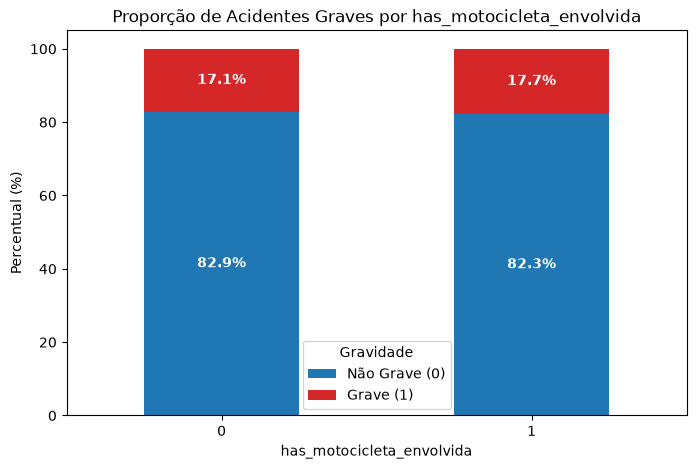

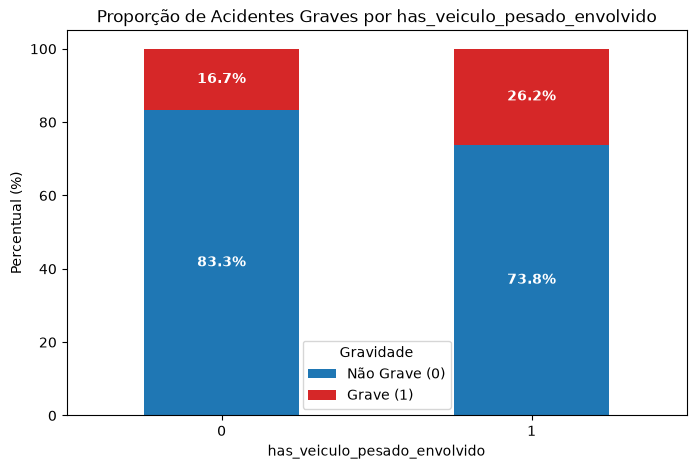

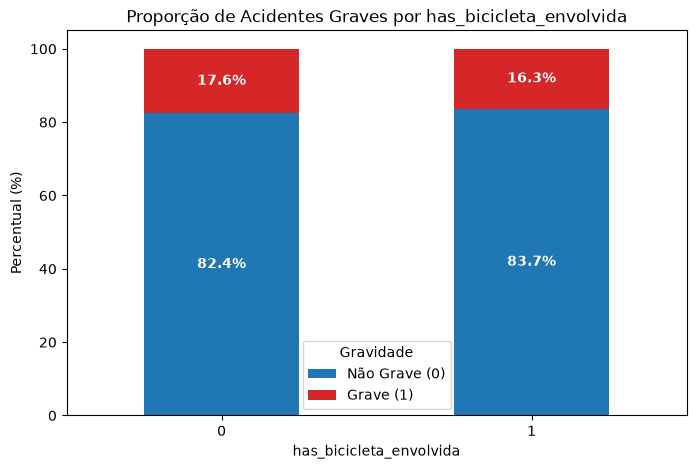

In [20]:
print('Variáveis relacionadas com veículos (apenas ocorrências com registro na tabela de veículos)')
df_abt_veiculo = df_abt[df_abt['has_registro_veiculo'] == 1]
plot_proporcao_gravidade(df_abt_veiculo, 'has_motocicleta_envolvida')
plot_proporcao_gravidade(df_abt_veiculo, 'has_veiculo_pesado_envolvido')
plot_proporcao_gravidade(df_abt_veiculo, 'has_bicicleta_envolvida')

Variáveis relacionadas com características da via (apenas ocorrências com registro na tabela via)


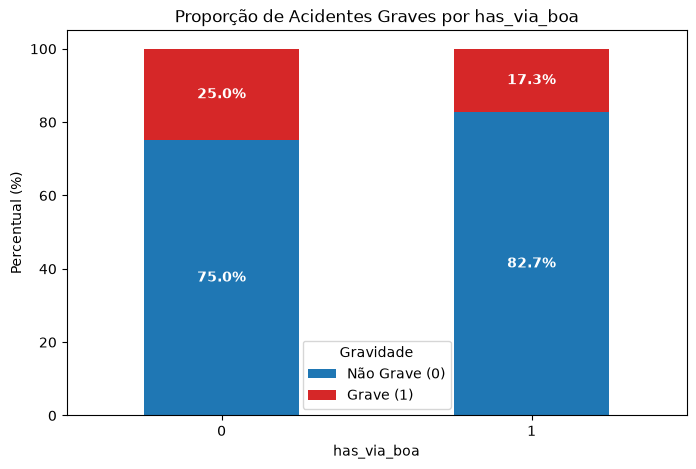

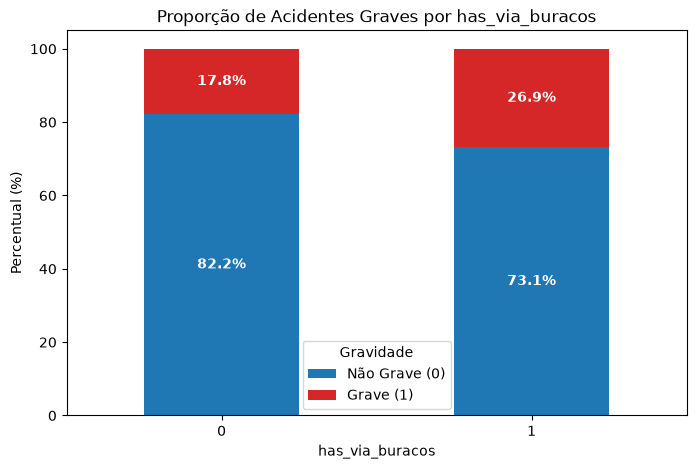

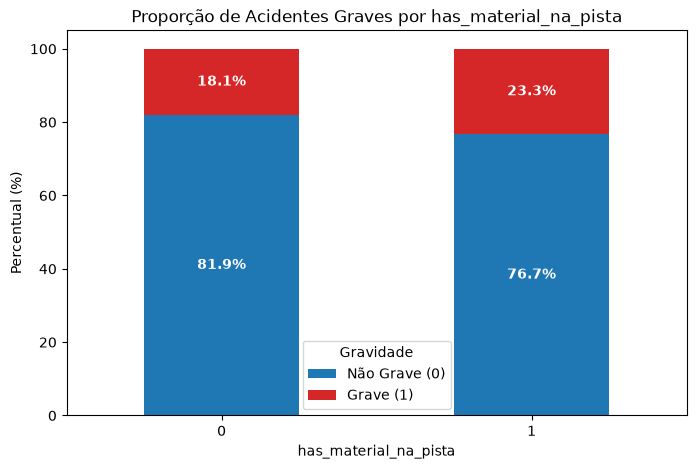

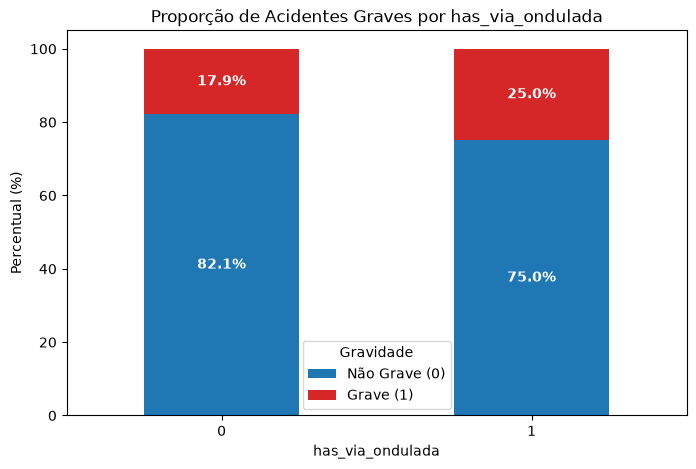

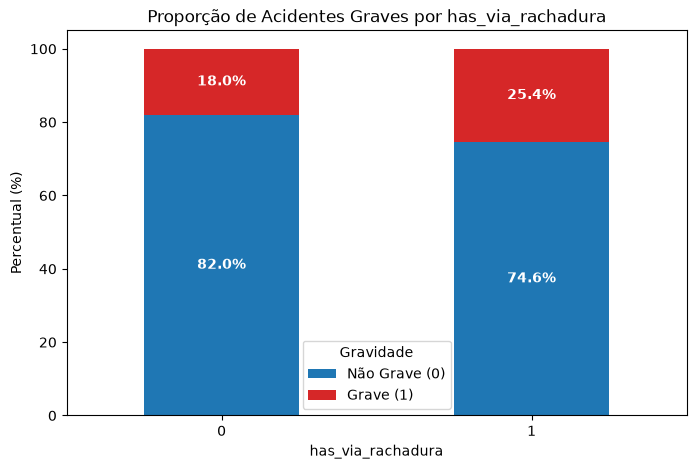

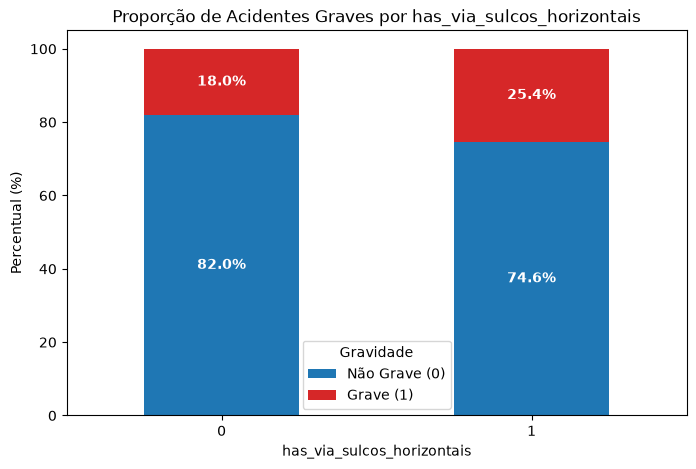

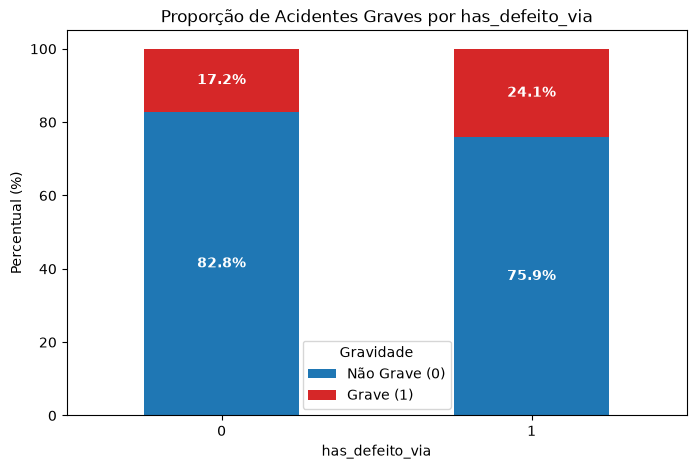

In [21]:
print('Variáveis relacionadas com características da via (apenas ocorrências com registro na tabela via)')
df_abt_via = df_abt[df_abt['has_registro_via'] == 1]
plot_proporcao_gravidade(df_abt_via, 'has_via_boa')
plot_proporcao_gravidade(df_abt_via, 'has_via_buracos')
plot_proporcao_gravidade(df_abt_via, 'has_material_na_pista')
plot_proporcao_gravidade(df_abt_via, 'has_via_ondulada')
plot_proporcao_gravidade(df_abt_via, 'has_via_rachadura')
plot_proporcao_gravidade(df_abt_via, 'has_via_sulcos_horizontais')
plot_proporcao_gravidade(df_abt_via, 'has_defeito_via')

Variáveis relacionadas com condicões da via (apenas ocorrências com registro na tabela condicoes)


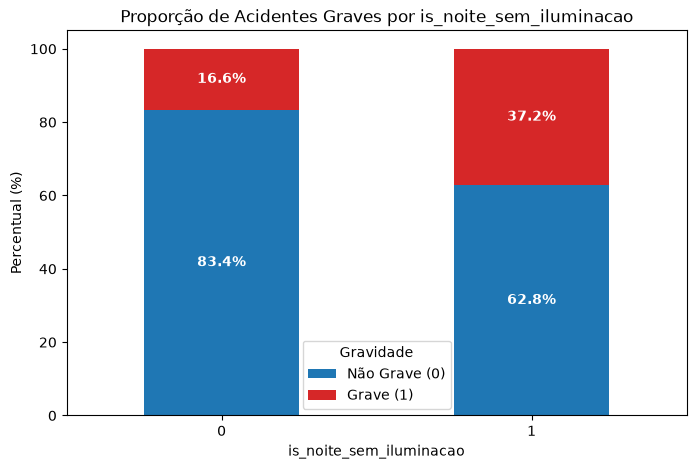

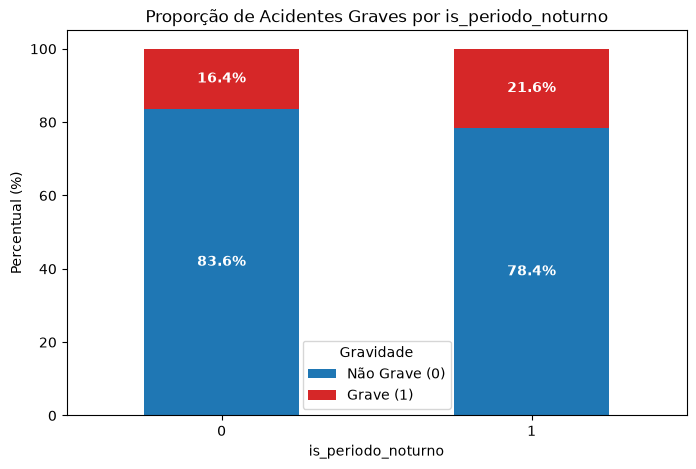

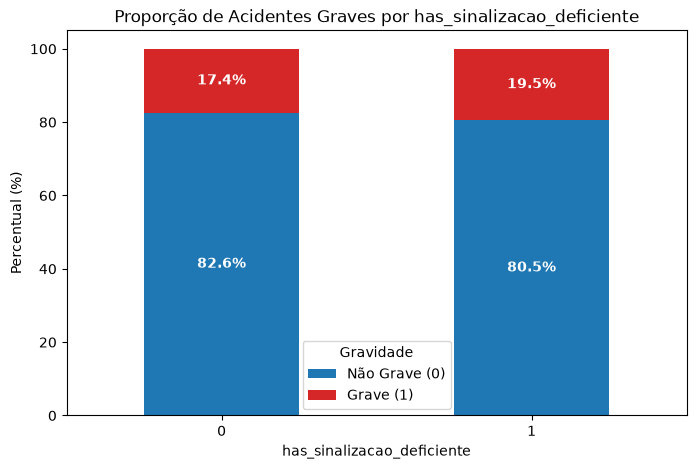

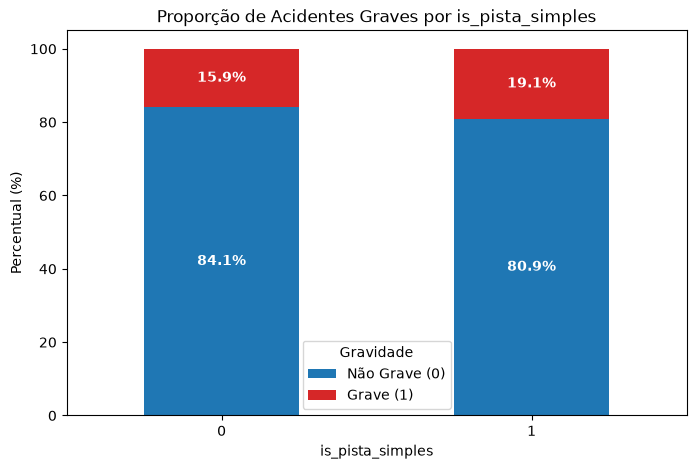

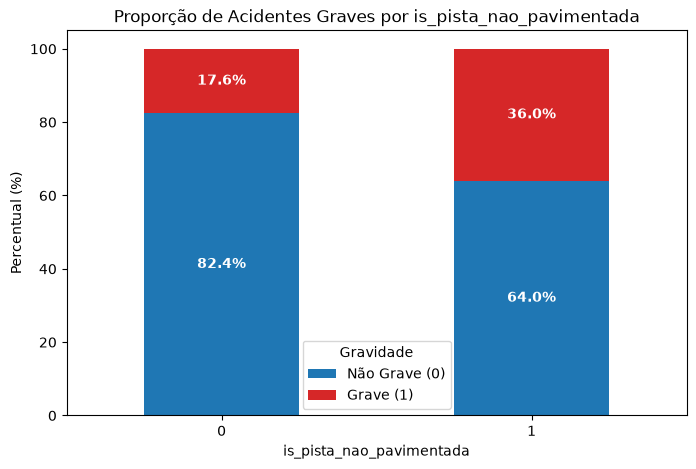

In [22]:
print('Variáveis relacionadas com condicões da via (apenas ocorrências com registro na tabela condicoes)')
df_abt_condicoes = df_abt[df_abt['has_registro_condicoes'] == 1]
plot_proporcao_gravidade(df_abt_condicoes, 'is_noite_sem_iluminacao')
plot_proporcao_gravidade(df_abt_condicoes, 'is_periodo_noturno')
plot_proporcao_gravidade(df_abt_condicoes, 'has_sinalizacao_deficiente')
plot_proporcao_gravidade(df_abt_condicoes, 'is_pista_simples')
plot_proporcao_gravidade(df_abt_condicoes, 'is_pista_nao_pavimentada')

Os gráficos das variáveis de via, condições e veículos consideram apenas as ocorrências com registro na respectiva tabela. Na base completa, as ocorrências sem registro aparecem com todas as flags iguais a 0, o que mascarava as relações: por exemplo, considerando só as ocorrências com registro, a proporção de acidentes graves é maior quando a via não está em boas condições.

Variáveis relacionadas com vítimas


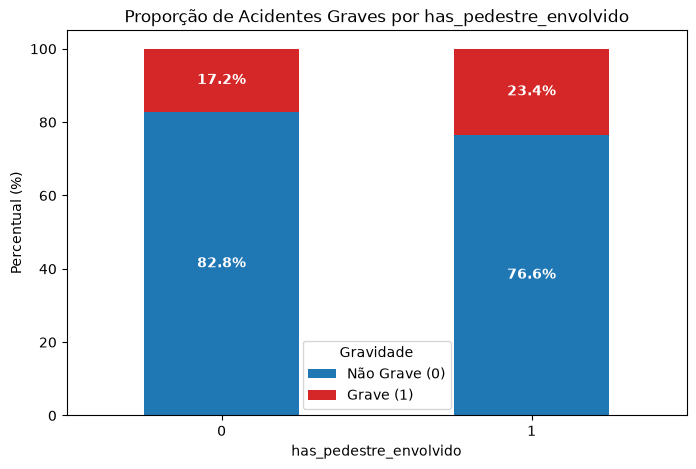

In [23]:
print('Variáveis relacionadas com vítimas')
plot_proporcao_gravidade(df_abt, 'has_pedestre_envolvido')

Variáveis relacionadas com a ocorrência em si


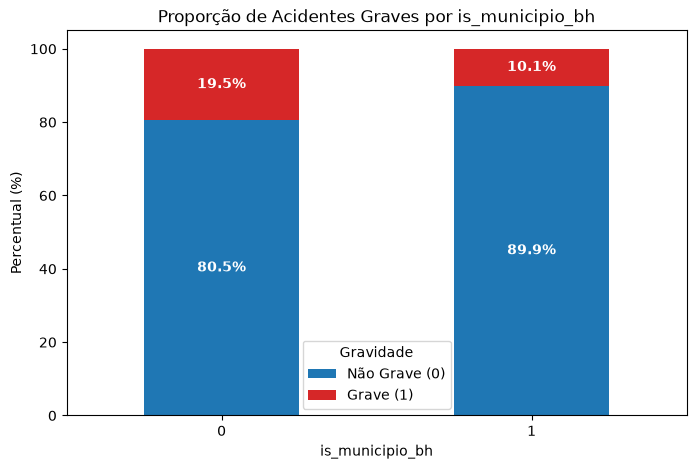

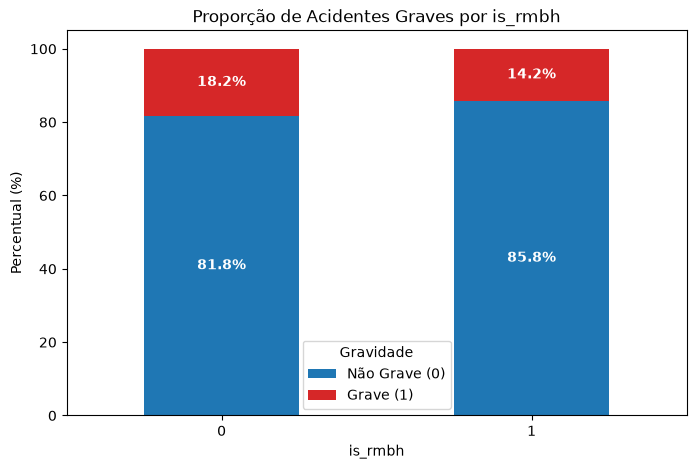

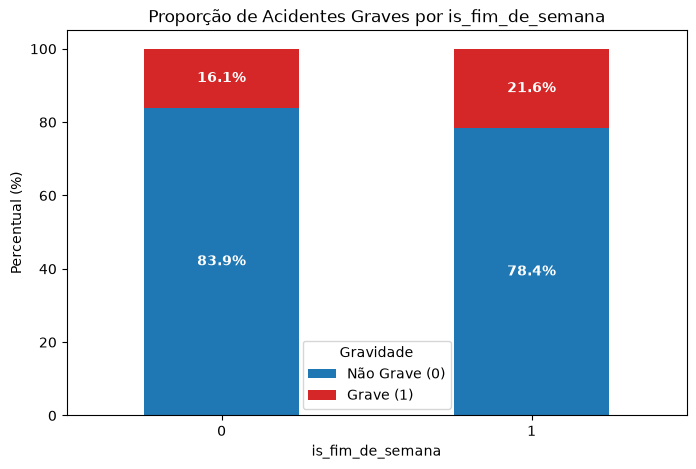

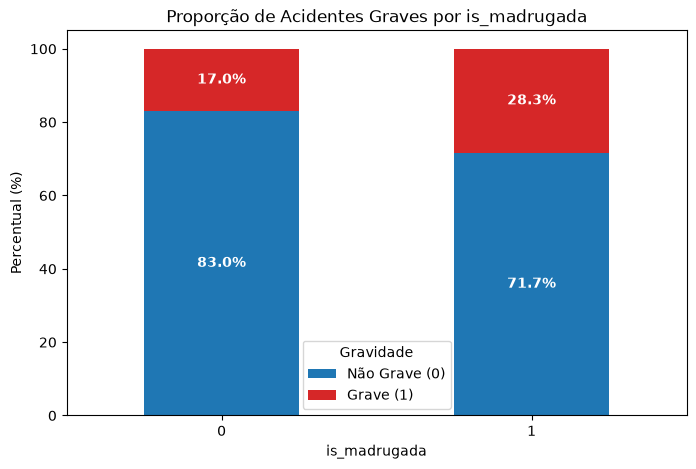

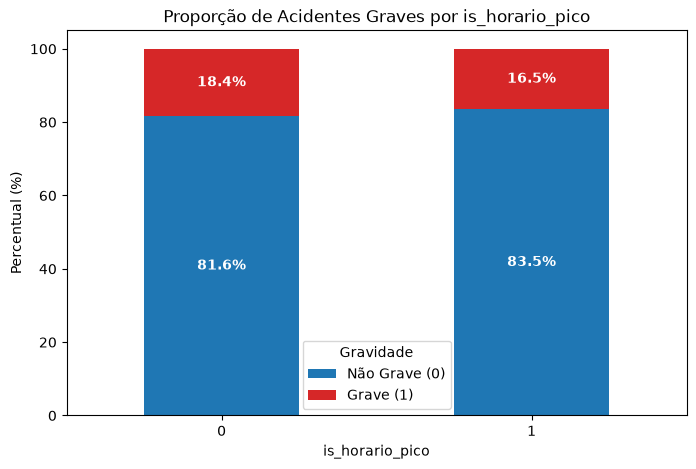

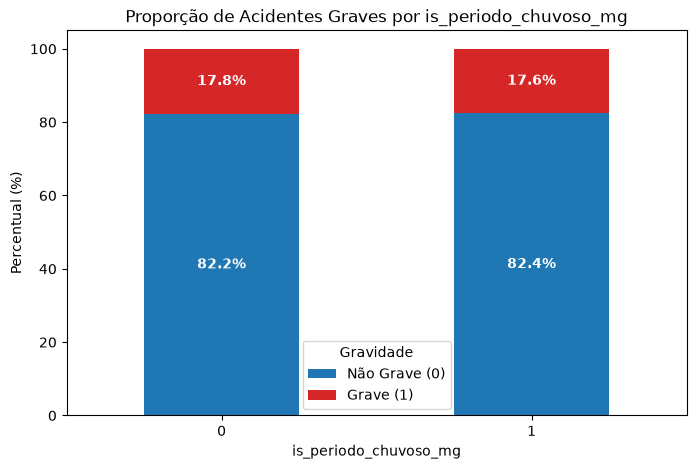

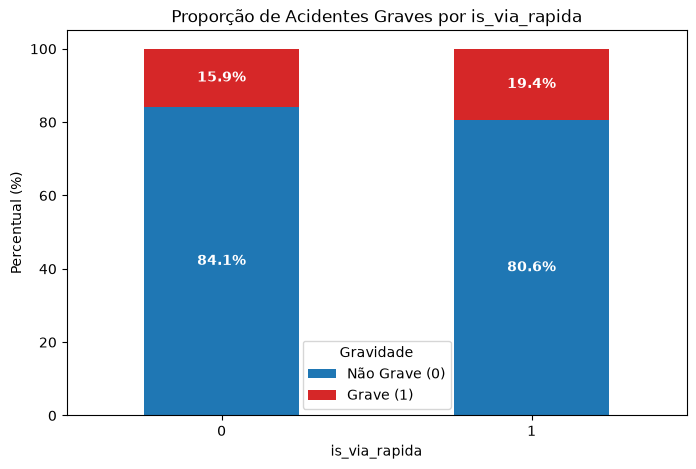

In [24]:
print('Variáveis relacionadas com a ocorrência em si')
plot_proporcao_gravidade(df_abt, 'is_municipio_bh')
plot_proporcao_gravidade(df_abt, 'is_rmbh')
plot_proporcao_gravidade(df_abt, 'is_fim_de_semana')
plot_proporcao_gravidade(df_abt, 'is_madrugada')
plot_proporcao_gravidade(df_abt, 'is_horario_pico')
plot_proporcao_gravidade(df_abt, 'is_periodo_chuvoso_mg')
plot_proporcao_gravidade(df_abt, 'is_via_rapida')

Presença de registro nas tabelas secundárias


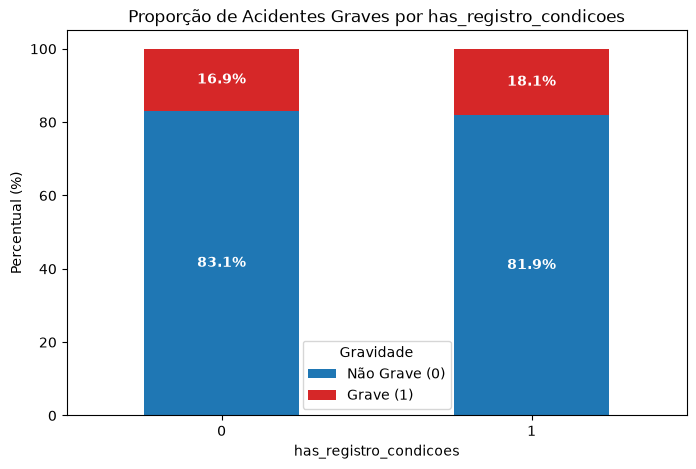

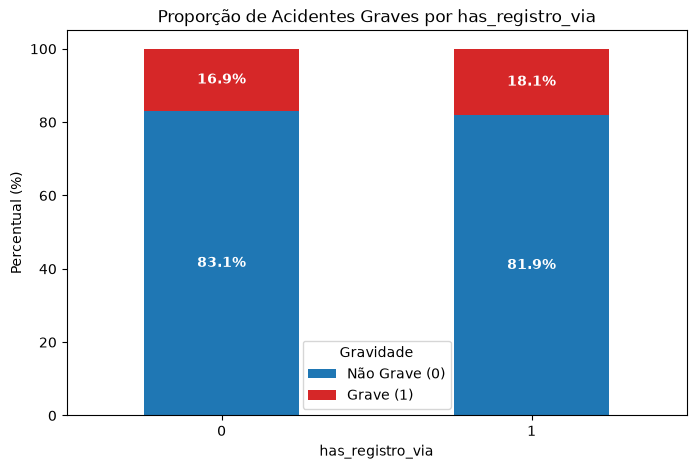

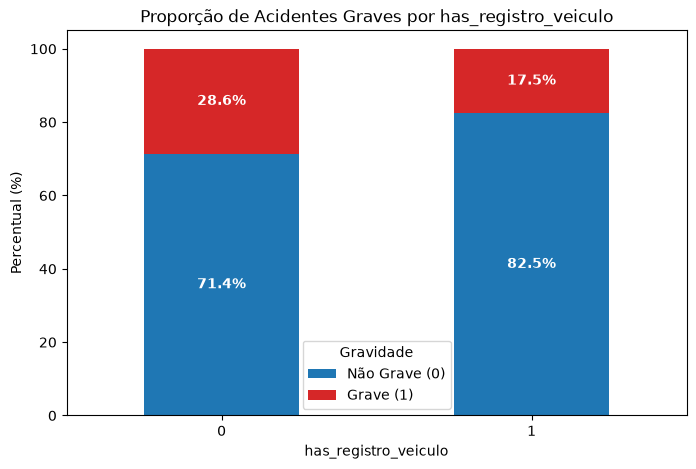

In [25]:
print('Presença de registro nas tabelas secundárias')
plot_proporcao_gravidade(df_abt, 'has_registro_condicoes')
plot_proporcao_gravidade(df_abt, 'has_registro_via')
plot_proporcao_gravidade(df_abt, 'has_registro_veiculo')

## 2. Distribuição de Variáveis Contínuas

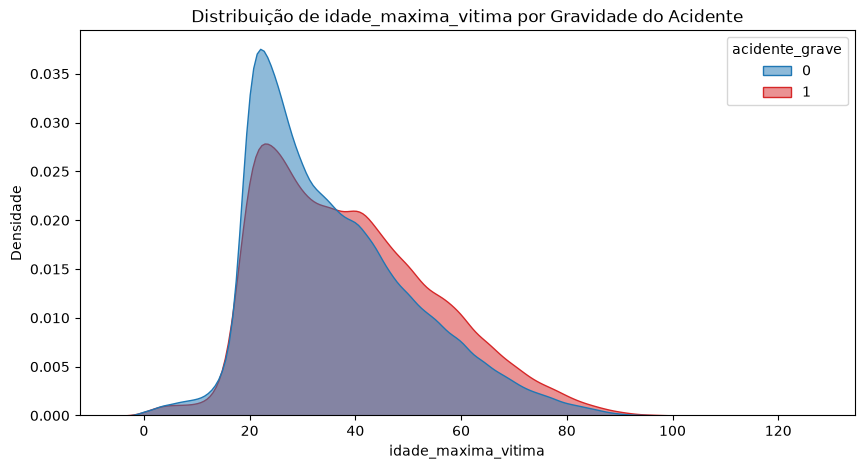

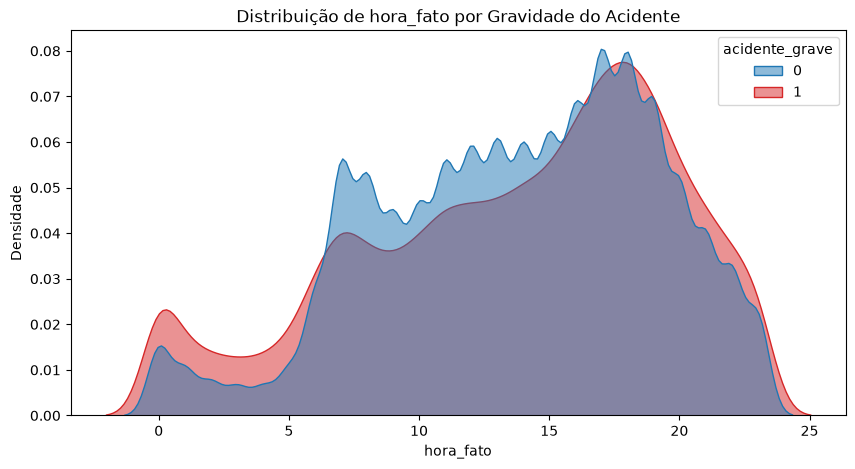

In [26]:
from src.visualization import plot_densidade_numerica

plot_densidade_numerica(df_abt, 'idade_maxima_vitima')
plot_densidade_numerica(df_abt, 'hora_fato')

In [27]:
print('Percentual de acidentes graves por hora do fato:')
display((df_abt.groupby('hora_fato')['acidente_grave'].mean() * 100).round(1))

Percentual de acidentes graves por hora do fato:


hora_fato
0     30.0
1     25.5
2     28.2
3     29.1
4     30.3
5     26.7
6     20.4
7     14.4
8     13.4
9     14.9
10    16.0
11    15.5
12    15.0
13    14.7
14    16.0
15    16.3
16    17.5
17    17.2
18    18.3
19    18.5
20    19.3
21    20.1
22    20.1
23    22.4
Name: acidente_grave, dtype: float64

Como as curvas são normalizadas separadamente para cada classe (common_norm=False), o gráfico compara a distribuição de cada variável dentro dos acidentes graves e dentro dos não graves, e não as quantidades absolutas. A distribuição de `idade_maxima_vitima` dos acidentes graves está deslocada para idades mais altas, e a de `hora_fato` concentra relativamente mais acidentes graves entre cerca de 20h e 5h. Em termos de taxa, a proporção de acidentes graves nesse intervalo é superior à média (ver tabela por hora). Vale notar que `idade_maxima_vitima` tende a crescer com o número de vítimas, que também está associado à gravidade.

## 3. Heatmap

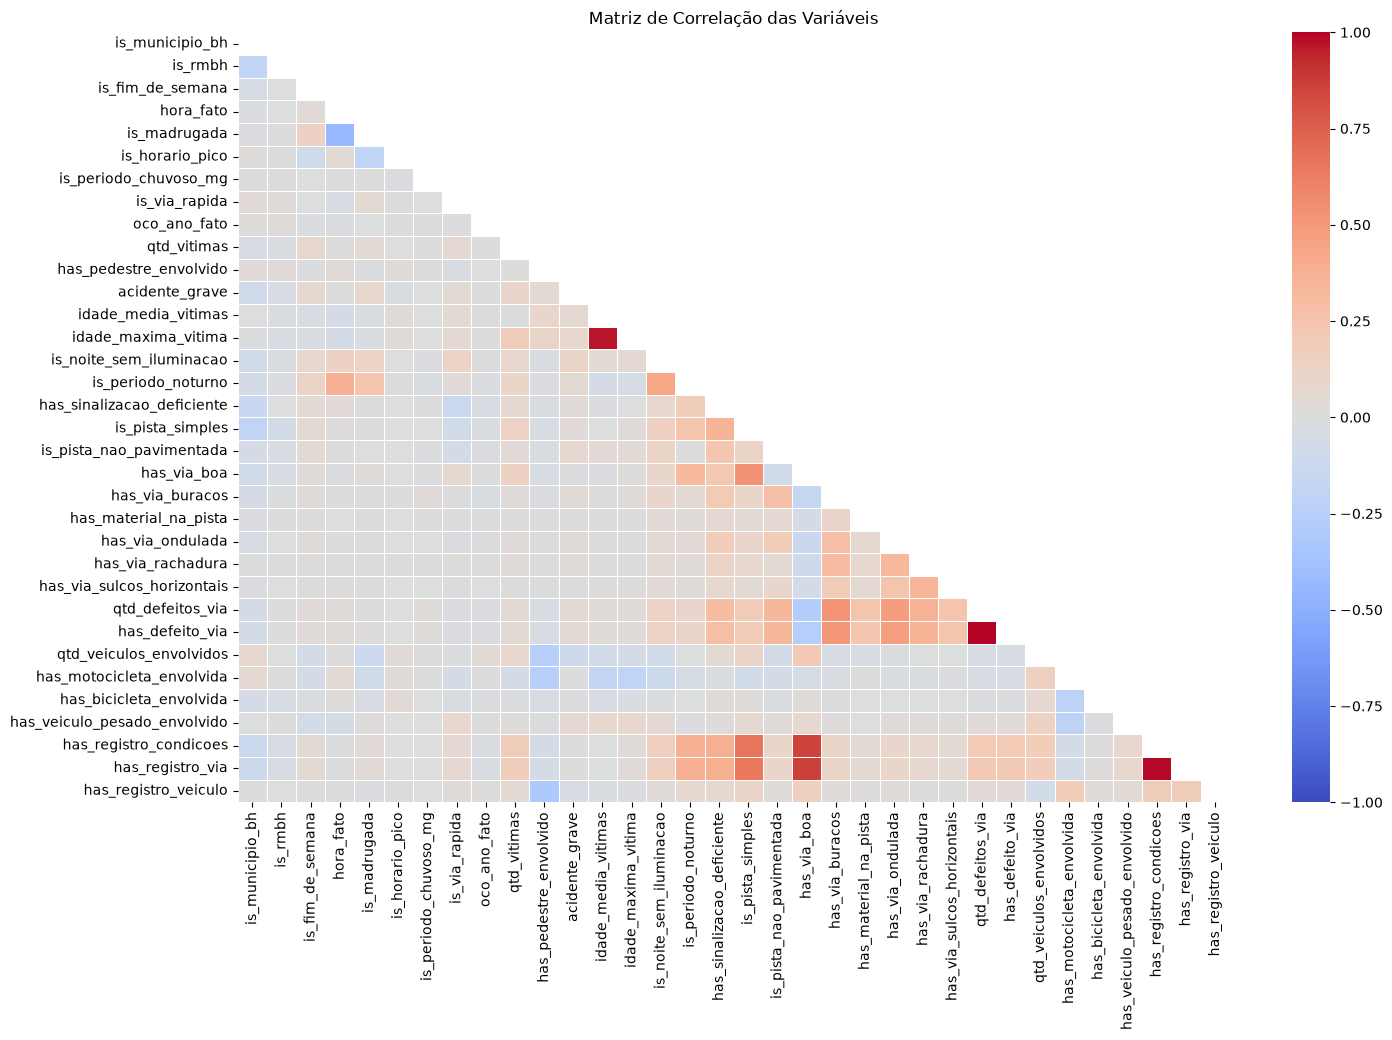

In [28]:
from src.visualization import plot_matriz_correlacao

plot_matriz_correlacao(df_abt)

Observações:
- O gráfico identifica redundâncias nos dados, marcadas pela correlação positiva máxima (em vermelho escuro) entre os atributos `idade_media_vitimas` e `idade_maxima_vitima`, assim como entre `has_defeito_via` e `qtd_defeitos_via`. Para evitar a problemas na fase de modelagem, uma variável de cada um desses pares precisará ser descartada antes da fase de treinamento.
- Do outro lado, verifica-se uma correlação negativa (tons de azul) entre `has_via_boa` e as variáveis que evidenciam problemas de infraestrutura (`has_defeito_via`, `has_via_buracos`, `has_via_ondulada`). Assim como existe uma correlação negativa entre as variáveis `has_motocicleta_envolvida` e `has_bicicleta_envolvida` e a variável de veículos pesados (`has_veiculo_pesado_envolvido`), evidenciando as diferentes naturezas desses sinistros. 
- As correlações da variável alvo `acidente_grave` com as demais variáveis são baixas (as maiores, em módulo, com `qtd_vitimas` e `is_noite_sem_iluminacao`). Isso é esperado com um alvo desbalanceado e flags binárias raras: o coeficiente fica pequeno mesmo quando a proporção de graves muda bastante entre os grupos, como mostram os gráficos de barra. Correlações pareadas baixas indicam que nenhuma variável isolada separa bem as classes, mas não permitem concluir que as relações são não lineares nem que modelos lineares terão desempenho inferior. Por isso, a comparação entre modelos lineares (Regressão Logística) e não lineares (Random Forest, XGBoost etc.) será feita empiricamente na etapa de modelagem.

## 4. Análise Geoespacial 

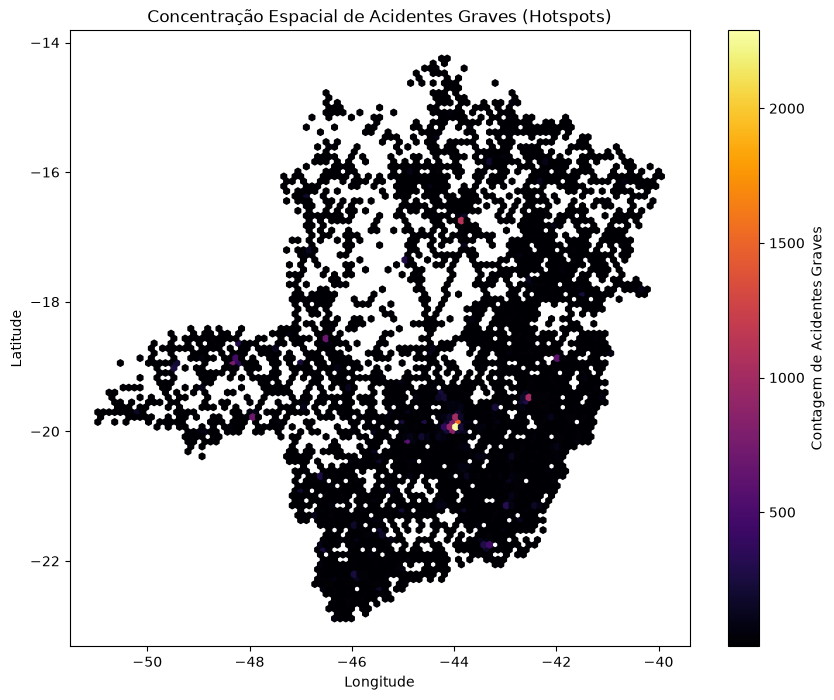

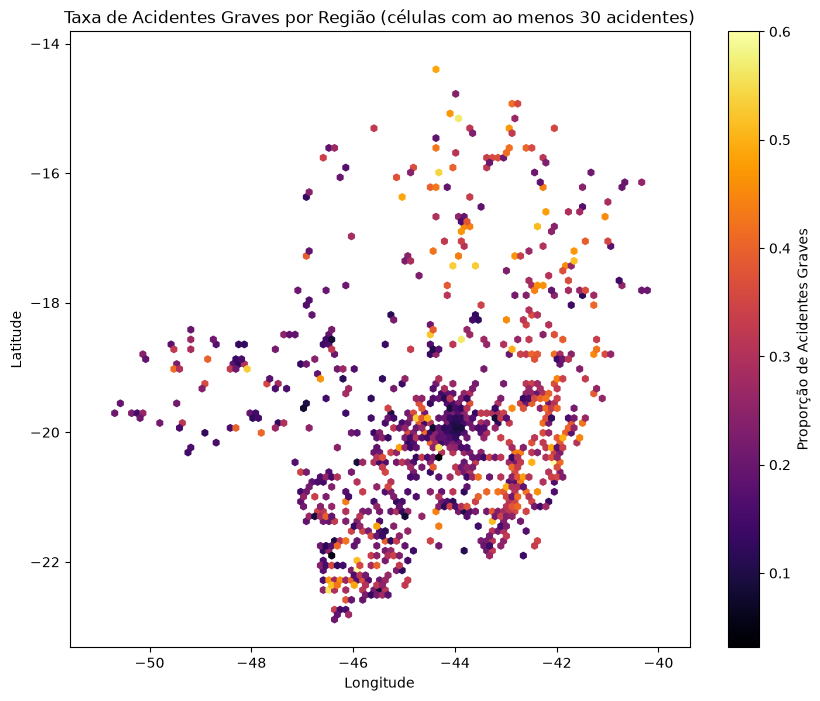

In [29]:
from src.visualization import plot_mapa_calor_hexagonal, plot_taxa_gravidade_hexagonal

plot_mapa_calor_hexagonal(df_abt)
plot_taxa_gravidade_hexagonal(df_abt)

O primeiro mapa mostra a contagem absoluta de acidentes graves, fortemente concentrada na RMBH e na capital (próximo à latitude -20 e longitude -44). Essa concentração reflete principalmente o volume de acidentes nessas áreas (exposição), e não maior risco de gravidade. O segundo mapa mostra a taxa de acidentes graves por célula (somente células com ao menos 30 acidentes): a capital apresenta taxas relativamente baixas, enquanto diversas áreas do interior apresentam taxas mais altas, o que é consistente com o gráfico de `is_municipio_bh` (proporção de graves menor na capital). Assim, as variáveis de localização são relevantes por diferenciarem o risco, mas no sentido oposto ao sugerido pelo mapa de contagem: acidentes na capital tendem a ser menos graves.